# 21 — Evaluación: prueba, importancia de variables y tres versiones del modelo
Punto **3** del informe. Tres preguntas:

1. **¿Qué tan bien predicen los modelos datos que nunca vieron?** Se usa por primera vez el 20 % de prueba, que ningún modelo vio.
2. **¿Qué variables usa el modelo?** Importancia **por permutación**: se desordena una variable (se barajan sus valores
   entre filas) y se mide cuánto cae el ROC-AUC. Si cae mucho, el modelo dependía de ella; si no cae, la ignoraba.
   Sirve para cualquier modelo, incluido el SVM, que no tiene importancias propias. Se mide en los pliegues de validación
   del **entrenamiento**, no en la prueba, para que elegir las variables no «espíe» los datos con que se evalúa.
3. **¿Cuántas variables hacen falta?** Se comparan tres versiones: las **19 originales**, las **27 con ingeniería** y
   solo las **5 más importantes**.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/modelado.ipynb
import warnings
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold, cross_val_score

warnings.filterwarnings("ignore", category=FutureWarning)
datos = cargar_conjunto()
part = pd.read_csv(MODELO_DIR / "particion.csv")
assert (part[OBJETIVO].to_numpy() == datos[OBJETIVO].to_numpy()).all()
tr = part.index[part["particion"] == "entrenamiento"]
te = part.index[part["particion"] == "prueba"]
y_tr, y_te = datos.loc[tr, OBJETIVO], datos.loc[te, OBJETIVO]
hp = leer_hp()
metricas_cv = pd.read_csv(MODELO_DIR / "metricas_cv.csv")
ajustado_cv = metricas_cv[metricas_cv["configuracion"] == "ajustado"].set_index("modelo")
MEJOR = ajustado_cv["roc_auc"].idxmax()
print(len(tr), "entrenamiento,", len(te), "prueba; mejor modelo en validación cruzada:", MEJOR)

992 entrenamiento, 248 prueba; mejor modelo en validación cruzada: Bagging


## 3.1 Métricas en la prueba
| métrica | pregunta que responde |
|---|---|
| exactitud | de todos los procesos, ¿qué parte clasificó bien? |
| precisión | de los que marcó «acumula mora», ¿cuántos acumulaban de verdad? |
| recall (sensibilidad) | de los que acumulaban, ¿a cuántos detectó? |
| F1 | equilibrio entre precisión y recall |
| ROC-AUC | ¿ordena bien a los que acumulan por encima de los que no? (sin elegir umbral) |

In [2]:
ajustados, filas = {}, []
for nombre in MODELOS:
    m = modelo(nombre, COMPLETA, hp).fit(datos.loc[tr, COMPLETA], y_tr)
    ajustados[nombre] = m
    pred = m.predict(datos.loc[te, COMPLETA])
    filas.append({"modelo": nombre, "familia": FAMILIAS[nombre][0],
                  "exactitud": accuracy_score(y_te, pred),
                  "precision": precision_score(y_te, pred, zero_division=0),
                  "recall": recall_score(y_te, pred), "f1": f1_score(y_te, pred, zero_division=0),
                  "roc_auc": roc_auc_score(y_te, puntaje(m, datos.loc[te, COMPLETA])),
                  "roc_auc_cv": ajustado_cv.loc[nombre, "roc_auc"]})
metricas_test = pd.DataFrame(filas)
metricas_test.to_csv(MODELO_DIR / "metricas_test.csv", index=False)
display(metricas_test.set_index("modelo").round(3))

,familia,exactitud,precision,recall,f1,roc_auc,roc_auc_cv
modelo,,,,,,,
Línea base (clase mayoritaria),referencia,0.508,0.000,0.000,0.000,0.500,0.500
Regresión logística,referencia,0.657,0.643,0.680,0.661,0.716,0.730
SVM,SVM,0.661,0.648,0.680,0.664,0.735,0.729
Bagging,Bagging,0.661,0.644,0.697,0.669,0.729,0.753
Random Forest,Bagging,0.653,0.632,0.705,0.667,0.731,0.753
AdaBoost,Boosting,0.629,0.603,0.721,0.657,0.700,0.728
Gradient Boosting,Boosting,0.645,0.633,0.664,0.648,0.736,0.744
Stacking,Stacking,0.661,0.646,0.689,0.667,0.741,0.753


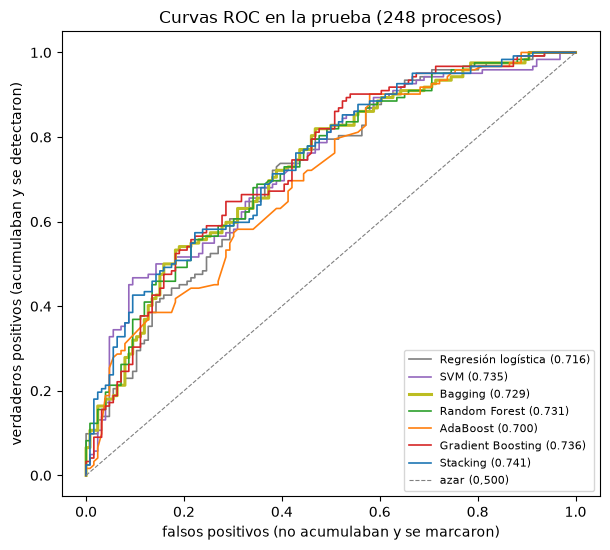

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
colores = {"Regresión logística": "tab:gray", "SVM": "tab:purple", "Bagging": "tab:olive", "Random Forest": "tab:green",
           "AdaBoost": "tab:orange", "Gradient Boosting": "tab:red", "Stacking": "tab:blue"}
for nombre, color in colores.items():
    fpr, tpr, _ = roc_curve(y_te, puntaje(ajustados[nombre], datos.loc[te, COMPLETA]))
    auc = metricas_test.set_index("modelo").loc[nombre, "roc_auc"]
    ax.plot(fpr, tpr, color=color, lw=2.2 if nombre == MEJOR else 1.2, label=f"{nombre} ({auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=0.8, label="azar (0,500)")
ax.set_xlabel("falsos positivos (no acumulaban y se marcaron)")
ax.set_ylabel("verdaderos positivos (acumulaban y se detectaron)")
ax.set_title(f"Curvas ROC en la prueba ({len(te)} procesos)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
guardar_figura(fig, "nb21_1.png")
plt.show()

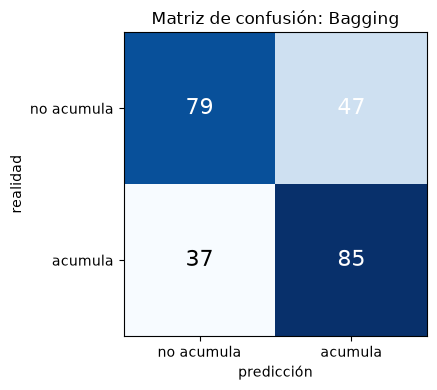

In [4]:
pred_mejor = ajustados[MEJOR].predict(datos.loc[te, COMPLETA])
cm = confusion_matrix(y_te, pred_mejor)
pd.DataFrame(cm, index=["real: no acumula", "real: acumula"], columns=["predice: no", "predice: acumula"]).to_csv(
    MODELO_DIR / "matriz_confusion.csv")
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["no acumula", "acumula"])
ax.set_yticks([0, 1], ["no acumula", "acumula"])
ax.set_xlabel("predicción")
ax.set_ylabel("realidad")
ax.set_title(f"Matriz de confusión: {MEJOR}")
plt.tight_layout()
guardar_figura(fig, "nb21_2.png")
plt.show()
assert cm.sum() == len(te)

## 3.2 Importancia de las variables
Por permutación sobre el mejor modelo (5 pliegues × 10 barajadas por variable). Como comparación, la importancia por
**impureza** del Random Forest (cuánto ayuda cada variable a separar las clases en los cortes de los árboles; las
columnas one-hot de una categoría se suman). La impureza tiende a favorecer variables con muchos valores distintos;
por eso la selección usa la permutación.

In [5]:
imp = importancia_permutacion_cv(MEJOR, COMPLETA, datos.loc[tr].reset_index(drop=True), y_tr.reset_index(drop=True), hp)
rf = ajustados["Random Forest"]
nombres_salida = rf.named_steps["pre"].get_feature_names_out()
impureza = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nombres_salida)
impureza_var = {c: impureza[[n for n in nombres_salida if n == f"num__{c}" or n.startswith(f"cat__{c}_")]].sum()
                for c in COMPLETA}
imp["importancia_impureza_rf"] = pd.Series(impureza_var)
imp["nombre"] = [NOMBRES[c] for c in imp.index]
imp["grupo"] = ["original" if c in ORIGINALES else "ingeniería" for c in imp.index]
imp["rango"] = range(1, len(imp) + 1)
imp.index.name = "variable"
imp.to_csv(MODELO_DIR / "importancia.csv")
TOP5 = list(imp.index[:5])
(MODELO_DIR / "top5.json").write_text(json.dumps({"modelo_importancia": MEJOR, "variables": TOP5}, ensure_ascii=False, indent=2),
                                      encoding="utf-8")
display(imp.round(4))
print("las 5 más importantes:", TOP5)
assert abs(imp["importancia_impureza_rf"].sum() - 1) < 1e-9

,importancia,desvio_entre_pliegues,importancia_impureza_rf,nombre,grupo,rango
variable,,,,,,
ingresos_por_juzgado,0.0391,0.0049,0.1478,ingresos por juzgado,ingeniería,1
presion_stock,0.0389,0.0101,0.1307,presión del stock,ingeniería,2
stock_por_juzgado,0.0113,0.0061,0.0826,stock por juzgado,ingeniería,3
materia_homologada,0.0074,0.0047,0.0429,materia,original,4
ingresos_totales,0.0069,0.0037,0.0648,ingresos del año,original,5
log_ingresos,0.0056,0.0037,0.0800,log de los ingresos,ingeniería,6
recurso_juzgados_publicados,0.0043,0.0045,0.0343,juzgados del territorio,original,7
num_juzgados_pagina,0.0041,0.0051,0.0576,juzgados (materia y territorio),original,8
departamento_derivado,0.0034,0.0027,0.0227,departamento,original,9


las 5 más importantes: ['ingresos_por_juzgado', 'presion_stock', 'stock_por_juzgado', 'materia_homologada', 'ingresos_totales']


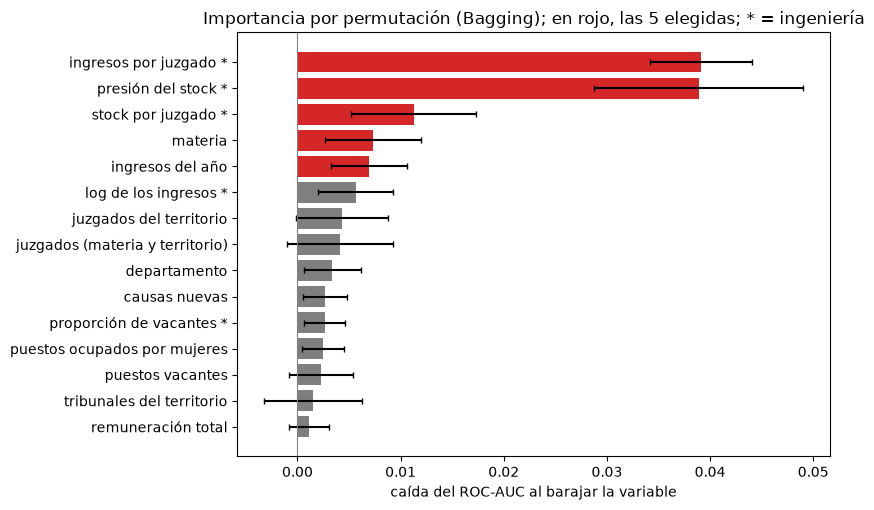

In [6]:
vista = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
colores_barras = ["tab:red" if c in TOP5 else "tab:gray" for c in vista.index]
ax.barh([f"{vista.loc[c, 'nombre']}" + (" *" if c in INGENIERIA else "") for c in vista.index], vista["importancia"],
        xerr=vista["desvio_entre_pliegues"], color=colores_barras, ecolor="black", capsize=2)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("caída del ROC-AUC al barajar la variable")
ax.set_title(f"Importancia por permutación ({MEJOR}); en rojo, las 5 elegidas; * = ingeniería")
plt.tight_layout()
guardar_figura(fig, "nb21_3.png")
plt.show()

## 3.3 Tres versiones: 19, 27 y 5 variables
Cada modelo se entrena con cada conjunto de variables, con los hiperparámetros del notebook 20. Se reporta el ROC-AUC
de validación cruzada (entrenamiento) y el de la prueba.

In [7]:
VERSIONES = {"originales (19)": ORIGINALES, "con ingeniería (27)": COMPLETA, "5 más importantes": TOP5}
assert len(ORIGINALES) == 19 and len(COMPLETA) == 27 and len(TOP5) == 5
filas = []
for version, cols in VERSIONES.items():
    for nombre in [m for m in MODELOS if not m.startswith("Línea")]:
        cv_auc = cross_val_score(modelo(nombre, cols, hp), datos.loc[tr, cols], y_tr, cv=CV5, scoring="roc_auc", n_jobs=-1)
        m = modelo(nombre, cols, hp).fit(datos.loc[tr, cols], y_tr)
        filas.append({"version": version, "n_variables": len(cols), "modelo": nombre, "roc_auc_cv": cv_auc.mean(),
                      "roc_auc_cv_desvio": cv_auc.std(),
                      "roc_auc_prueba": roc_auc_score(y_te, puntaje(m, datos.loc[te, cols])),
                      "exactitud_prueba": accuracy_score(y_te, m.predict(datos.loc[te, cols]))})
versiones = pd.DataFrame(filas)
versiones.to_csv(MODELO_DIR / "comparacion_versiones.csv", index=False)
display(versiones.pivot_table(index="modelo", columns="version", values=["roc_auc_cv", "roc_auc_prueba"]).round(3))

roc_auc_cv                                      \
version             5 más importantes con ingeniería (27) originales (19)   
modelo                                                                      
AdaBoost                        0.714               0.728           0.709   
Bagging                         0.704               0.753           0.735   
Gradient Boosting               0.712               0.744           0.732   
Random Forest                   0.705               0.753           0.739   
Regresión logística             0.659               0.730           0.584   
SVM                             0.649               0.729           0.595   
Stacking                        0.705               0.753           0.737   

                       roc_auc_prueba                                      
version             5 más importantes con ingeniería (27) originales (19)  
modelo                                                                     
AdaBoost                        0.660               0.700           0.704  
Bagging                         0.658               0.729           0.712  
Gradient Boosting               0.663               0.736           0.739  
Random Forest                   0.662               0.731           0.715  
Regresión logística             0.619               0.716           0.604  
SVM                             0.631               0.735           0.639  
Stacking                        0.664               0.741           0.718

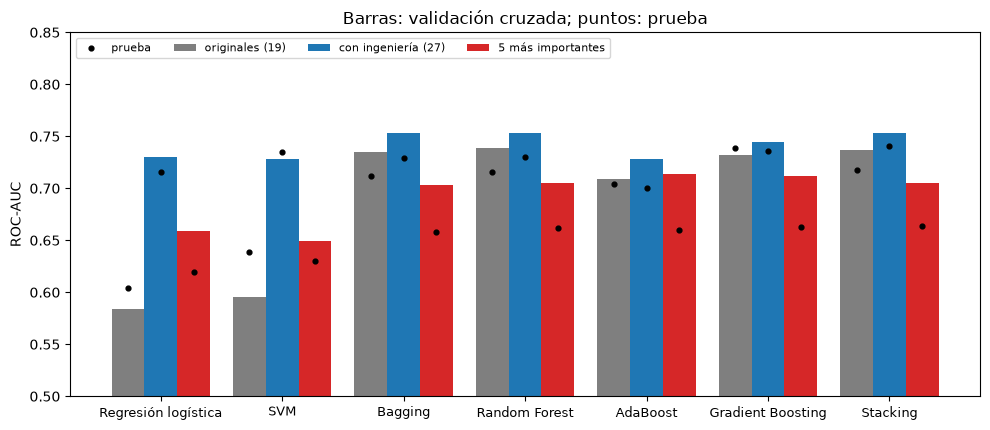

In [8]:
modelos_v = [m for m in MODELOS if not m.startswith("Línea")]
fig, ax = plt.subplots(figsize=(10, 4.4))
pos = np.arange(len(modelos_v))
for k, (version, color) in enumerate(zip(VERSIONES, ["tab:gray", "tab:blue", "tab:red"])):
    v = versiones[versiones["version"] == version].set_index("modelo").loc[modelos_v]
    ax.bar(pos + (k - 1) * 0.27, v["roc_auc_cv"], 0.27, color=color, label=version)
    ax.scatter(pos + (k - 1) * 0.27, v["roc_auc_prueba"], color="black", s=12, zorder=3,
               label="prueba" if k == 0 else None)
ax.set_xticks(pos, modelos_v, fontsize=9)
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("ROC-AUC")
ax.set_title("Barras: validación cruzada; puntos: prueba")
ax.legend(fontsize=8, ncol=4, loc="upper left")
plt.tight_layout()
guardar_figura(fig, "nb21_4.png")
plt.show()

## 3.4 Control de robustez: procesos que el modelo nunca vio
El mismo tipo de proceso (por ejemplo, «divorcio») aparece en varios departamentos. Si el modelo solo «recordara» cada
tipo, le iría bien en la validación normal pero mal con un tipo nuevo. Con **validación por grupos** (`GroupKFold`)
todas las filas de un mismo tipo de proceso quedan del mismo lado: el modelo se evalúa con tipos que no vio al entrenar.

In [9]:
grupos = datos.loc[tr, "tipo_proceso"]
filas = []
for version, cols in VERSIONES.items():
    for nombre in [MEJOR, "Random Forest", "SVM"]:
        g = cross_val_score(modelo(nombre, cols, hp), datos.loc[tr, cols], y_tr, groups=grupos, cv=GroupKFold(5),
                            scoring="roc_auc", n_jobs=-1)
        normal = versiones.set_index(["version", "modelo"]).loc[(version, nombre), "roc_auc_cv"]
        filas.append({"version": version, "modelo": nombre, "roc_auc_cv_normal": normal, "roc_auc_por_grupos": g.mean(),
                      "diferencia": g.mean() - normal})
robustez = pd.DataFrame(filas).drop_duplicates(["version", "modelo"])
robustez.to_csv(MODELO_DIR / "robustez_grupos.csv", index=False)
display(robustez.round(3))
print(datos["tipo_proceso"].nunique(), "tipos de proceso distintos")

,version,modelo,roc_auc_cv_normal,roc_auc_por_grupos,diferencia
0,originales (19),Bagging,0.735,0.730,-0.005
1,originales (19),Random Forest,0.739,0.728,-0.010
2,originales (19),SVM,0.595,0.552,-0.043
3,con ingeniería (27),Bagging,0.753,0.741,-0.013
4,con ingeniería (27),Random Forest,0.753,0.735,-0.018
5,con ingeniería (27),SVM,0.729,0.698,-0.031
6,5 más importantes,Bagging,0.704,0.692,-0.012
7,5 más importantes,Random Forest,0.705,0.681,-0.024
8,5 más importantes,SVM,0.649,0.613,-0.036


87 tipos de proceso distintos


## Lectura
- **En la prueba (248 procesos que ningún modelo vio) los resultados se sostienen.** Todos superan a la línea base, con
  ROC-AUC entre 0,700 (AdaBoost) y 0,741 (Stacking). Bagging, el mejor en validación cruzada, da 0,729 en la prueba: un poco
  menos que en la validación (0,753), lo normal cuando se elige el mejor de varios candidatos. Con 248 filas, diferencias
  de 0,01 entre modelos están dentro del ruido; ningún modelo gana con claridad.
- **Matriz de confusión de Bagging:** de los 122 procesos que acumularon, detectó 85 (recall 0,70); de los 132 que marcó
  como «acumula», 85 acertaron (precisión 0,64). Se equivoca más por alarmas falsas (47) que por casos perdidos (37).
  Exactitud 0,66: dos de cada tres procesos bien clasificados.
- **Importancia:** lo que más usa el modelo son **tres variables de ingeniería**: ingresos por juzgado (al barajarla el
  AUC cae 0,039), presión del stock (0,039) y stock por juzgado (0,011); siguen la materia (0,007) y los ingresos del año
  (0,007). Son las 5 elegidas. Personal, vacantes, remuneración y ámbito casi no importan (< 0,003), y las causas
  atendidas llegan a ser negativas: barajarlas no empeora nada. La impureza del Random Forest coincide en las dos primeras.
- **Tres versiones:** con ingeniería (27) es la mejor en todos los modelos (Bagging: 0,753 en validación, 0,729 en
  prueba). Las 19 originales bajan poco a los árboles (0,735) y mucho a la logística y al SVM (0,58 y 0,60): **los
  cocientes que los árboles aproximan solos, los modelos lineales y el SVM no los pueden construir**. Las 5 más importantes
  pierden alrededor de 0,05 en validación y 0,07 en la prueba (Bagging: 0,704 y 0,658): el modelo pequeño es más simple de
  usar y explicar, pero pierde parte de la señal que estaba repartida entre las otras 22 variables.
- **Robustez:** al evaluar con tipos de proceso que el modelo no vio (`GroupKFold`), Bagging con 27 variables baja de 0,753
  a 0,741 (−0,013) y Random Forest −0,018: el modelo no solo «recuerda» cada tipo de proceso, generaliza a tipos nuevos.
  El SVM es el que más cae (−0,03 a −0,04).
